# 02. Mini GPT, training, dan resume

Tujuan: melihat tensor yang masuk ke model, cara loss dihitung, konfigurasi training, serta bukti stop/resume baseline.

**Alur:** token -> embedding + posisi -> 6 decoder block -> logits -> loss -> gradient accumulation -> AdamW -> validation -> checkpoint.

Sel default menjalankan forward kecil dari model acak dan membaca hasil training yang sudah selesai.
Sel smoke di bagian akhir memakai `RUN_SMOKE = False`. Ubah hanya bila ingin memulai eksperimen GPU baru dengan log dan TRAIN ID baru.

In [1]:
from pathlib import Path
import sys, json, shutil, datetime
import pandas as pd
import torch
from IPython.display import display, Markdown, Image

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "configs/model.json").is_file() and (p / "src/models/minigpt.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Buka notebook dari folder proyek ini.")
if Path(sys.prefix).resolve() != (ROOT / ".venv").resolve():
    raise RuntimeError("Pilih kernel Mini GPT WebCodeGen dari .venv proyek ini.")
sys.path.insert(0, str(ROOT))
def load_json(relative):
    return json.loads((ROOT / relative).read_text(encoding="utf-8"))
print("Interpreter:", sys.executable)
print("Waktu eksekusi:", datetime.datetime.now(datetime.timezone(datetime.timedelta(hours=7))).isoformat())
print("PyTorch:", torch.__version__, "| CUDA:", torch.version.cuda)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

Interpreter: F:\Generative_AI\Vibe_Coding_Proyek_1\.venv\Scripts\python.exe
Waktu eksekusi: 2026-10-12T22:17:06.872587+07:00
PyTorch: 2.14.1+cu130 | CUDA: 13.0
GPU: NVIDIA GeForce RTX 5070


## 1. Arsitektur dari bobot acak

Setiap block memiliki LayerNorm, causal multi-head attention, residual, dan MLP GELU.
Causal mask melarang posisi melihat token masa depan. Learned positional embedding menandai urutan token.
Embedding token dan output head berbagi bobot. Model tidak memakai `nn.Transformer` atau checkpoint eksternal.

In [2]:
from src.models.minigpt import MiniGPT
from src.training.engine import seed_everything, loss_sum
model_config = load_json("configs/model.json")
seed_everything(42)
model = MiniGPT(model_config)
print(json.dumps(model_config, indent=2))
print(f"Parameter: {model.parameter_count():,}")
display(pd.DataFrame([{ "bagian": name, "parameter": sum(p.numel() for p in layer.parameters())}
                      for name, layer in model.named_children()]))
print("Jumlah tabel komponen tidak dijumlahkan sebagai total karena embedding dan head berbagi bobot.")

{
  "vocab_size": 8192,
  "block_size": 1024,
  "n_layer": 6,
  "n_head": 6,
  "n_embd": 384,
  "dropout": 0.1,
  "tie_embeddings": true,
  "initialization": "random normal mean 0 std 0.02; no pretrained weights"
}
Parameter: 14,186,496


,bagian,parameter
0,token_embedding,3145728
1,position_embedding,393216
2,embedding_dropout,0
3,blocks,10646784
4,final_norm,768
5,lm_head,3145728


Jumlah tabel komponen tidak dijumlahkan sebagai total karena embedding dan head berbagi bobot.


## 2. Forward kecil dan loss token

Gunakan 64 posisi dari blok train, tanpa mengubah bobot. Logits berukuran `[batch, waktu, vocabulary]`.
Cross entropy hanya menghitung label valid. Model pada sel ini masih acak, sehingga loss ini bukan hasil checkpoint baseline.

In [3]:
from src.data.dataset import PretrainingBlockDataset
token_file = ROOT / "data/processed/pretrain/train.tokens.bin"
if token_file.exists():
    example = PretrainingBlockDataset(token_file, model_config["block_size"])[0]
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model = model.to(device).eval()
    x = example["input_ids"][:64].unsqueeze(0).to(device)
    y = example["labels"][:64].unsqueeze(0).to(device)
    with torch.no_grad():
        logits = model(x)
        summed, count = loss_sum(logits, y)
    print("input:", tuple(x.shape), "| logits:", tuple(logits.shape))
    print("Token valid:", count, "| Loss model acak:", float(summed / count))
    del logits, x, y, model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
else:
    del model
    print("Cache lokal belum tersedia. Lewati forward, baca hasil historis pada bagian berikut.")

input: (1, 64) | logits: (1, 64, 8192)
Token valid: 64 | Loss model acak: 9.080720901489258


## 3. Target mask untuk SFT

Struktur sequence: `<bos> <prompt> instruksi <target> JSON <eos>`.
Label prompt dan padding diberi `-100`; hanya JSON dan EOS dihitung. JSON yang terlalu panjang ditolak utuh.
Contoh berikut adalah fixture belajar yang ditulis manual. Contoh ini tidak masuk dataset produksi atau status reviewed.

In [4]:
from tokenizers import Tokenizer
from src.data.dataset import encode_sft
tokenizer_path = ROOT / "data/tokenizer/tokenizer.json"
fixture_spec = {"schema_version": "1.0", "title": "Halo", "language": "id",
                "style_mode": "plain_css", "theme": {"primary": "#2563eb", "background": "#ffffff", "text": "#111827", "font": "sans"},
                "sections": [{"id": "hero-1", "type": "hero", "props": {"heading": "Halo", "text": "Selamat datang."}}], "interactions": []}
if tokenizer_path.exists():
    tokenizer = Tokenizer.from_file(str(tokenizer_path))
    ids, labels = encode_sft("Buat halaman perkenalan sederhana berbahasa Indonesia.",
                             json.dumps(fixture_spec, sort_keys=True, ensure_ascii=False, separators=(",", ":")),
                             tokenizer, model_config["block_size"])
    print("Posisi:", len(ids), "| Target valid:", sum(i != -100 for i in labels))
    display(pd.DataFrame({"posisi": range(24), "input_token": [tokenizer.id_to_token(i) for i in ids[:24]],
                          "label_id": labels[:24], "dihitung_loss": [i != -100 for i in labels[:24]]}))
else:
    print("Tokenizer lokal belum tersedia.")

Posisi: 1024 | Target valid: 162


,posisi,input_token,label_id,dihitung_loss
0,0,<bos>,-100,False
1,1,<prompt>,-100,False
2,2,Bu,-100,False
3,3,at,-100,False
4,4,Ġh,-100,False
5,5,a,-100,False
6,6,la,-100,False
7,7,man,-100,False
8,8,Ġper,-100,False
9,9,k,-100,False


## 4. Konfigurasi dan siklus update

Batch 4 x accumulation 4 berarti satu update mengagregasi hingga 16 blok, sekitar 16.384 label valid.
Loss accumulation ditimbang dengan jumlah token valid. Gradient diperiksa finite dan di-clip sebelum AdamW.
Warmup 60 update diikuti cosine decay. Validation menggunakan 128 blok tetap, bukan test partition.
BF16 dipilih dari kemampuan RTX 5070 dan hasil profiling, bukan klaim batch maksimum.

In [5]:
train_config = load_json("configs/training_pretrain.json")
keys = ["precision", "batch_size", "gradient_accumulation", "max_steps", "warmup_steps", "learning_rate", "min_learning_rate", "weight_decay", "grad_clip", "validation_interval"]
display(pd.DataFrame([{k: train_config[k] for k in keys}]).T.rename(columns={0: "nilai"}))
steps = ["Ambil microbatch deterministik", "Forward dan loss token valid", "Backward untuk accumulation",
         "Periksa gradient, clip, AdamW", "Majukan scheduler dan data cursor", "Validation pada interval", "Simpan last/best dan laporan"]
display(pd.DataFrame({"urutan": range(1, len(steps)+1), "tindakan": steps}))

,nilai
precision,bf16
batch_size,4
gradient_accumulation,4
max_steps,1200
warmup_steps,60
learning_rate,0.0003
min_learning_rate,0.00003
weight_decay,0.1
grad_clip,1.0
validation_interval,100


,urutan,tindakan
0,1,Ambil microbatch deterministik
1,2,Forward dan loss token valid
2,3,Backward untuk accumulation
3,4,"Periksa gradient, clip, AdamW"
4,5,Majukan scheduler dan data cursor
5,6,Validation pada interval
6,7,Simpan last/best dan laporan


## 5. Run nyata: smoke, baseline, dan resume

TRAIN-002 menguji loop dengan 5 update. TRAIN-003 berhenti terencana pada step 200, lalu TRAIN-004 memulihkan model, optimizer, scheduler, RNG, dan cursor sampai step 1.200.
Waktu pada laporan mencakup run tersebut saja. Profiling dan evaluasi dicatat terpisah.

In [6]:
runs = [load_json(f"reports/training/TRAIN-{i:03d}.json") for i in [2, 3, 4]]
display(pd.DataFrame([{ "run": r["run_id"], "status": r["status"], "step": r["global_step"],
                       "validation_loss": r["final_validation"]["loss"], "detik": r["wall_seconds"],
                       "peak_allocated_GiB": r.get("peak_allocated_bytes", 0)/1024**3} for r in runs]))
parent, resumed = runs[1], runs[2]
print("Validation sebelum jeda:", parent["final_validation"]["loss"])
print("Validation setelah reload:", resumed["initial_validation"]["loss"])
print("Hash parent cocok:", parent["final_checkpoint_sha256"] == resumed["resume_parent_sha256"])
print("Token kumulatif:", f"{resumed['total_train_tokens']:,}")
print("GPU:", resumed["environment"]["gpu"])

,run,status,step,validation_loss,detik,peak_allocated_GiB
0,TRAIN-002,completed,5,8.700616,5.428763,1.971879
1,TRAIN-003,stopped_at_limit,200,2.220937,47.244114,2.027048
2,TRAIN-004,completed,1200,1.111391,227.016635,2.031747


Validation sebelum jeda: 2.220936931669712
Validation setelah reload: 2.220936931669712
Hash parent cocok: True
Token kumulatif: 19,657,265
GPU: NVIDIA GeForce RTX 5070


## 6. Kurva loss dan learning rate

Kurva berikut berasal dari 1.200 update TRAIN-003/004. Validation loss memakai subset tetap.
Penurunan loss kode belum membuktikan bahwa instruksi Indonesia menghasilkan PageSpec valid.

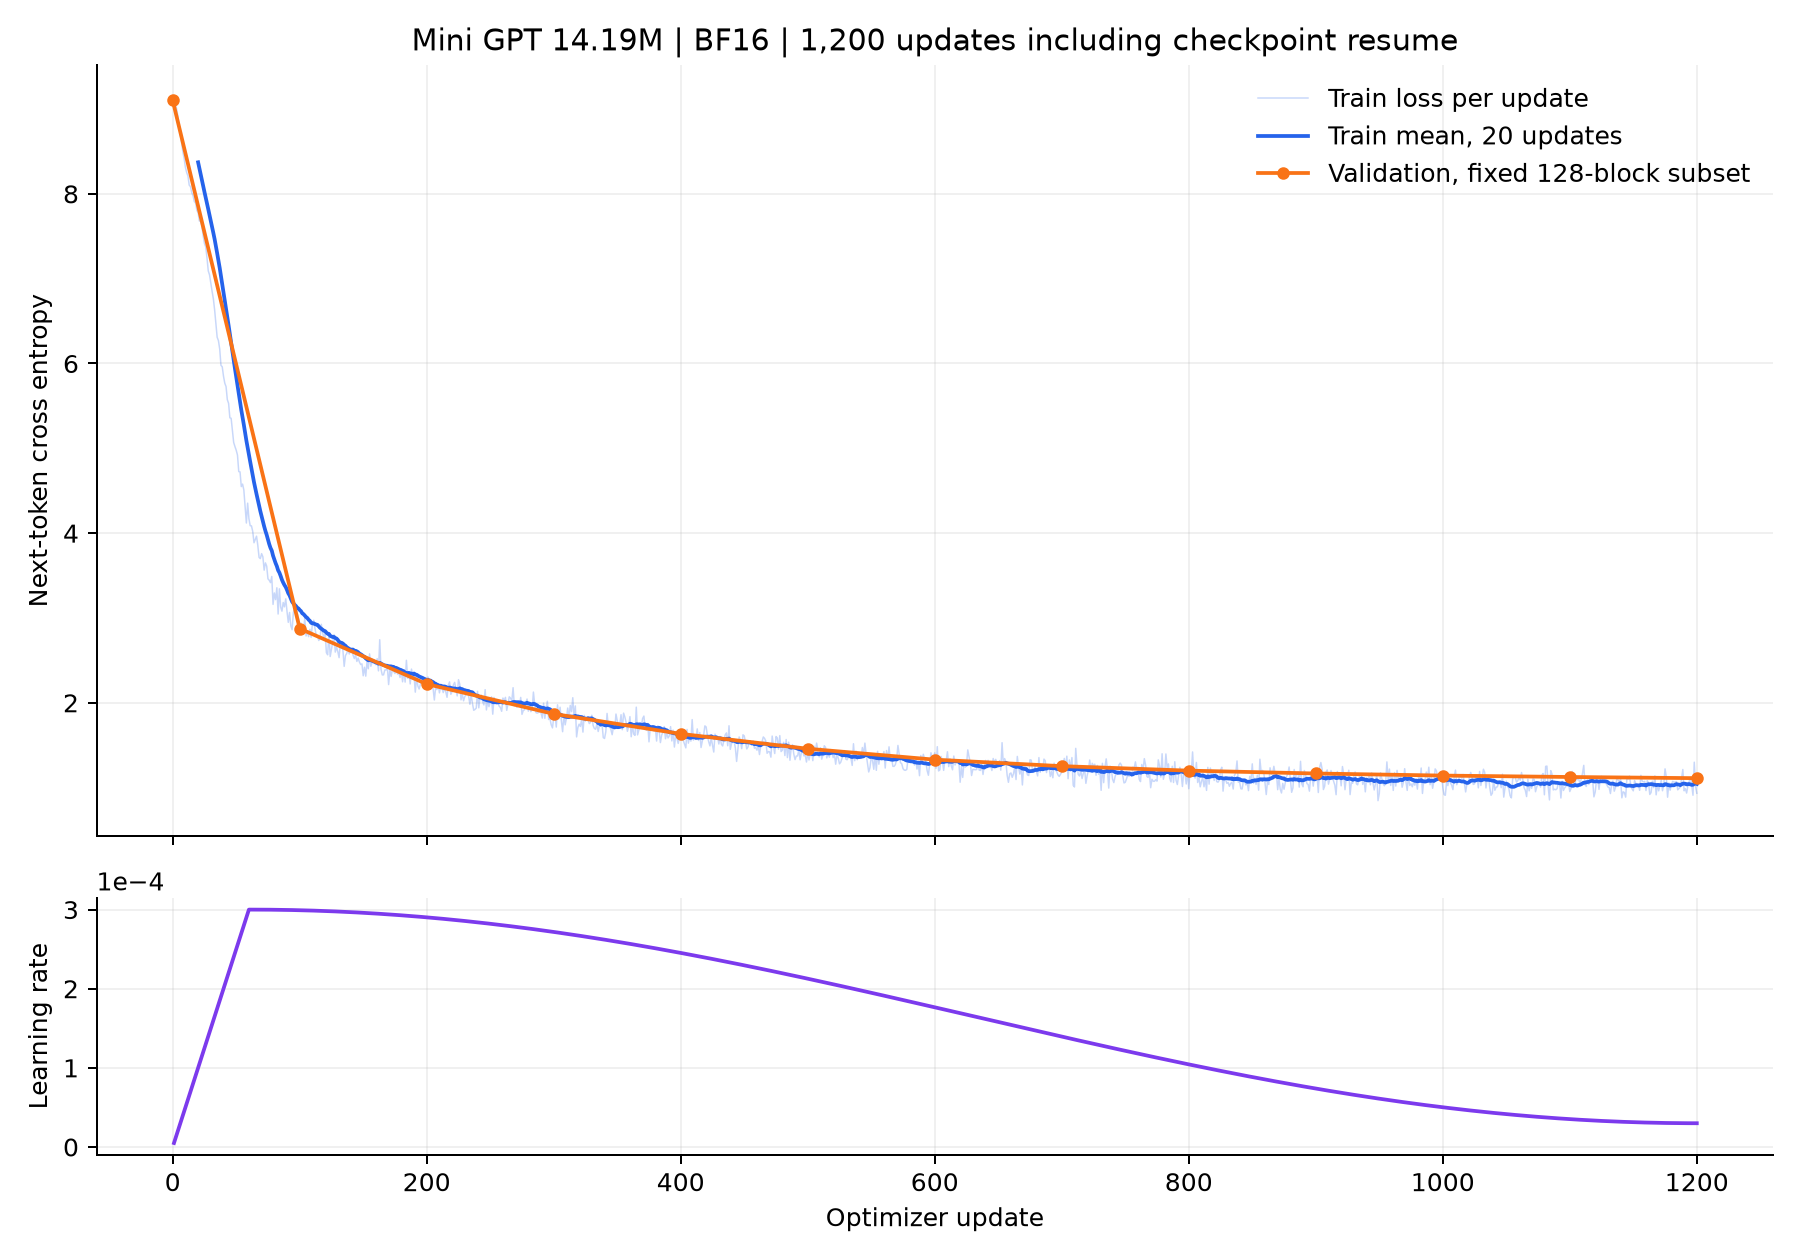

,step,loss,learning_rate,grad_norm,valid_tokens,data_cursor
0,1,9.093893,0.000005,4.255412,16384,4
199,200,2.203165,0.000290,0.959065,16384,800
200,201,2.303974,0.000290,0.838895,16384,804
1199,1200,0.933632,0.000030,0.575899,16384,4800


Train points: 1200 | Median token/detik: 77932.47


In [7]:
figure = ROOT / "reports/training/BASELINE_LOSS_2026-10-12.png"
display(Image(filename=str(figure)))
metric_paths = [ROOT / f"outputs/metrics/TRAIN-{i:03d}.jsonl" for i in [3, 4]]
if all(p.exists() for p in metric_paths):
    records = [json.loads(line) for p in metric_paths for line in p.read_text().splitlines()]
    metrics = pd.DataFrame([r for r in records if r["event"] == "train"])
    display(metrics[["step", "loss", "learning_rate", "grad_norm", "valid_tokens", "data_cursor"]].iloc[[0, 199, 200, -1]])
    print("Train points:", len(metrics), "| Median token/detik:", round(metrics["tokens_per_second"].median(), 2))
else:
    print("JSONL lokal tidak masuk Git. Grafik dan laporan ringkas historis tetap tersedia.")

## 7. Lihat isi checkpoint lokal

Checkpoint memuat bobot, optimizer, scheduler, RNG, config, lineage, step, dan cursor data.
Checksum diverifikasi sebelum load. Bobot checkpoint tetap lokal karena ukurannya besar.
Sel ini membaca metadata checkpoint tanpa mengubah model atau melakukan resume.

In [8]:
from src.training.engine import read_checkpoint
checkpoint = ROOT / "checkpoints/TRAIN-004/best.pt"
if checkpoint.exists():
    state = read_checkpoint(checkpoint)
    print("Isi:", list(state))
    print("Step:", state["global_step"], "| Data cursor:", state.get("data_cursor"))
    print("Lineage:", json.dumps(state.get("lineage", state.get("config", {}).get("lineage", {})), indent=2))
    del state
else:
    print("Checkpoint lokal belum tersedia. SHA baseline:", resumed["best_checkpoint_sha256"])

Isi:

 ['format_version', 'run_id', 'model', 'model_config', 'optimizer', 'scheduler', 'global_step', 'total_tokens', 'best_validation_loss', 'config', 'sampler', 'rng']
Step: 1200 | Data cursor: None
Lineage: {
  "tokenizer_sha256": "f7d5410d5963b3504bc09a4f6bf29e695cb8c6ba64041bfe1596a13cecb210d7",
  "pipeline_summary_sha256": "85f8f6994e70111a887dd60d7b8c70d80de1835ec66ecd8862381e023e5ed283",
  "data_sha256": {
    "train": "44eb1d883865917f5cafc448ac60592c002d9526de7e2579deca9ad50655e0c8",
    "validation": "5461629ba4b9bff9ec640a9b64ccb21466d2dacb96a948cea33629526f74d80e"
  },
  "validation_indices_sha256": "dd94b79817d7a88299f2042b2ba0bc8e11fa02c3f5c343be95d121a166865959",
  "train_blocks_or_examples": 18593,
  "validation_blocks_or_examples": 128,
  "smoke": false
}


## 8. Eksperimen smoke baru, pilihan eksplisit

Default di bawah tidak memulai training. Jika diubah menjadi True, trainer memilih TRAIN ID baru,
memverifikasi data/storage, memakai subset kecil selama 5 update, dan mencatat RUN baru.
Output sel smoke tersimpan di log eksperimen, bukan digabung dengan hasil baseline historis.

In [9]:
RUN_SMOKE = False
if RUN_SMOKE:
    import subprocess
    subprocess.run([sys.executable, "qa/run_logged.py", "--label", "notebook_smoke", "--",
                    sys.executable, "-m", "qa.train_minigpt", "--config", "configs/training_pretrain.json",
                    "--max-steps", "5", "--smoke"], cwd=ROOT, check=True)
else:
    print("RUN_SMOKE=False. Tidak ada training baru dari eksekusi notebook ini.")

RUN_SMOKE=False. Tidak ada training baru dari eksekusi notebook ini.


## 9. Verified copy dan lineage sebelum SFT

Baseline asli dipertahankan. RUN-076 menambahkan fingerprint corpus dan family pada copy baru, sebelum preparation SFT mengubah summary. Sel ini membaca laporan bukti. Hash payload berubah karena metadata, sedangkan bobot tetap identik. Format checkpoint baru memakai pointer menuju payload/manifest immutable; pembaca proyek memverifikasi semuanya.

In [10]:
migration = load_json("reports/training/TRAIN-004_lineage_migration.json")
display(pd.DataFrame([{k: migration[k] for k in ["status", "global_step", "model_tensors_identical", "optimizer_updates", "output_checkpoint"]}]))
print("Fingerprint pretraining:", migration["pretrain_fingerprint"]["sha256"])
print("SHA sumber:", migration["source_checkpoint_sha256"])
print("SHA payload copy:", migration["output_checkpoint_sha256"])

,status,global_step,model_tensors_identical,optimizer_updates,output_checkpoint
0,verified_copy,1200,True,0,checkpoints\TRAIN-004-VERIFIED\best.pt


Fingerprint pretraining: fd6e3b5a20b3214cfd9e6cc769f7c011d3209235731edb793b917e60ca8a371a
SHA sumber: 9f407be207c9b9090104d48243109a2c333d9609cd89e7584dd8ccd5d5b50486
SHA payload copy: 49e03ebb37f01619de9dc93a55f6828367d84fd34380986bfa15597d9583831c


Lanjut ke [03_evaluasi_dan_hasil.ipynb](03_evaluasi_dan_hasil.ipynb).
Command baseline, resume, dan SFT tersedia di [panduan training](../docs/TRAINING_GUIDE.md).
SFT produksi masih menunggu review manusia terhadap data instruksi.